# D-15: purchase_month 처리 — 미사용 확정

결정 근거는 decisions.md D-15 참고(2026-09-27 확정). 요약:

- Mann-Kendall(D-03용, 04_eda_day4 section 3-1)은 **단조추세**만 검정하므로 계절성 판단에는 부적합함 → 연도 무관 풀링(cal_month)으로 별도 재확인
- 풀링 기준 1~3월·11월에 late율 스파이크 관찰되었으나, **연도별(2017 vs 2018) 분리 결과 스파이크 시점이 서로 다름**(2017은 11월만, 2018은 2~3월만). 이 관측은 반복되는 달력 계절성일 가능성을 낮추지만, **분석기간이 20개월(연도당 관측 1회)뿐이라 계절 효과와 연도 효과를 통계적으로 분리할 수는 없음** — 2017-11 스파이크를 블랙프라이데이로 보는 것도 검증되지 않은 추정이며, 반복 계절성인지 개별 사건인지는 이 데이터로 확정할 수 없음. **어느 쪽이든 미사용 판단에는 영향 없음**(반복 계절성이면 순수 EDA로는 못 잡는 구조적 한계이고, 개별 사건이면 애초에 인코딩 대상이 아님) [2026-09-30 보강]
- purchase_month를 계절 인코딩(sin/cos·범주형)으로 넣으면 이 일회성 사건을 반복 패턴으로 오학습할 위험이 기대 이득보다 큼 → **미사용** 확정
- 미확인 사항: 2018년 2~3월 스파이크 원인 미상 — log.md Day 5 "미확인 항목"에 기록(2026-09-30에 추후 확인 필요로 기록)

⚠️ 9~12월은 분석기간(2017-01~2018-08)상 2017년 데이터만 존재해 애초에 연도 비교가 불가능한 구간임 — 아래 표에서 2018년 9~12월이 전부 NaN인 이유.

## 0. 데이터 로드

In [1]:
import pandas as pd
from src import my_plot

master = pd.read_parquet("data/processed/master.parquet")
assert master["order_id"].is_unique and len(master) == 96204

## 1. 달력월별 late율 — 연도 무관 풀링

1~2단계 Mann-Kendall은 "20개월 전체가 오르막/내리막이냐"만 보므로, 매년 반복되는 "특정 달" 패턴(계절성)은 이 검정으로 못 잡는다. 그래서 연도를 무시하고 월(1~12)만으로 풀링해 스파이크가 있는지 먼저 육안 확인한다.

               n  late_rate  low_rate
cal_month                            
1           7819   0.054355  0.135414
2           8209   0.118894  0.177033
3           9549   0.151220  0.185224
4           9101   0.050214  0.120770
5          10294   0.053332  0.105186
6           9231   0.017983  0.102363
7          10028   0.031512  0.097791
8          10544   0.048843  0.094807
9           4150   0.043855  0.102720
10          4478   0.041760  0.110661
11          7288   0.124040  0.165676
12          5513   0.074551  0.144296


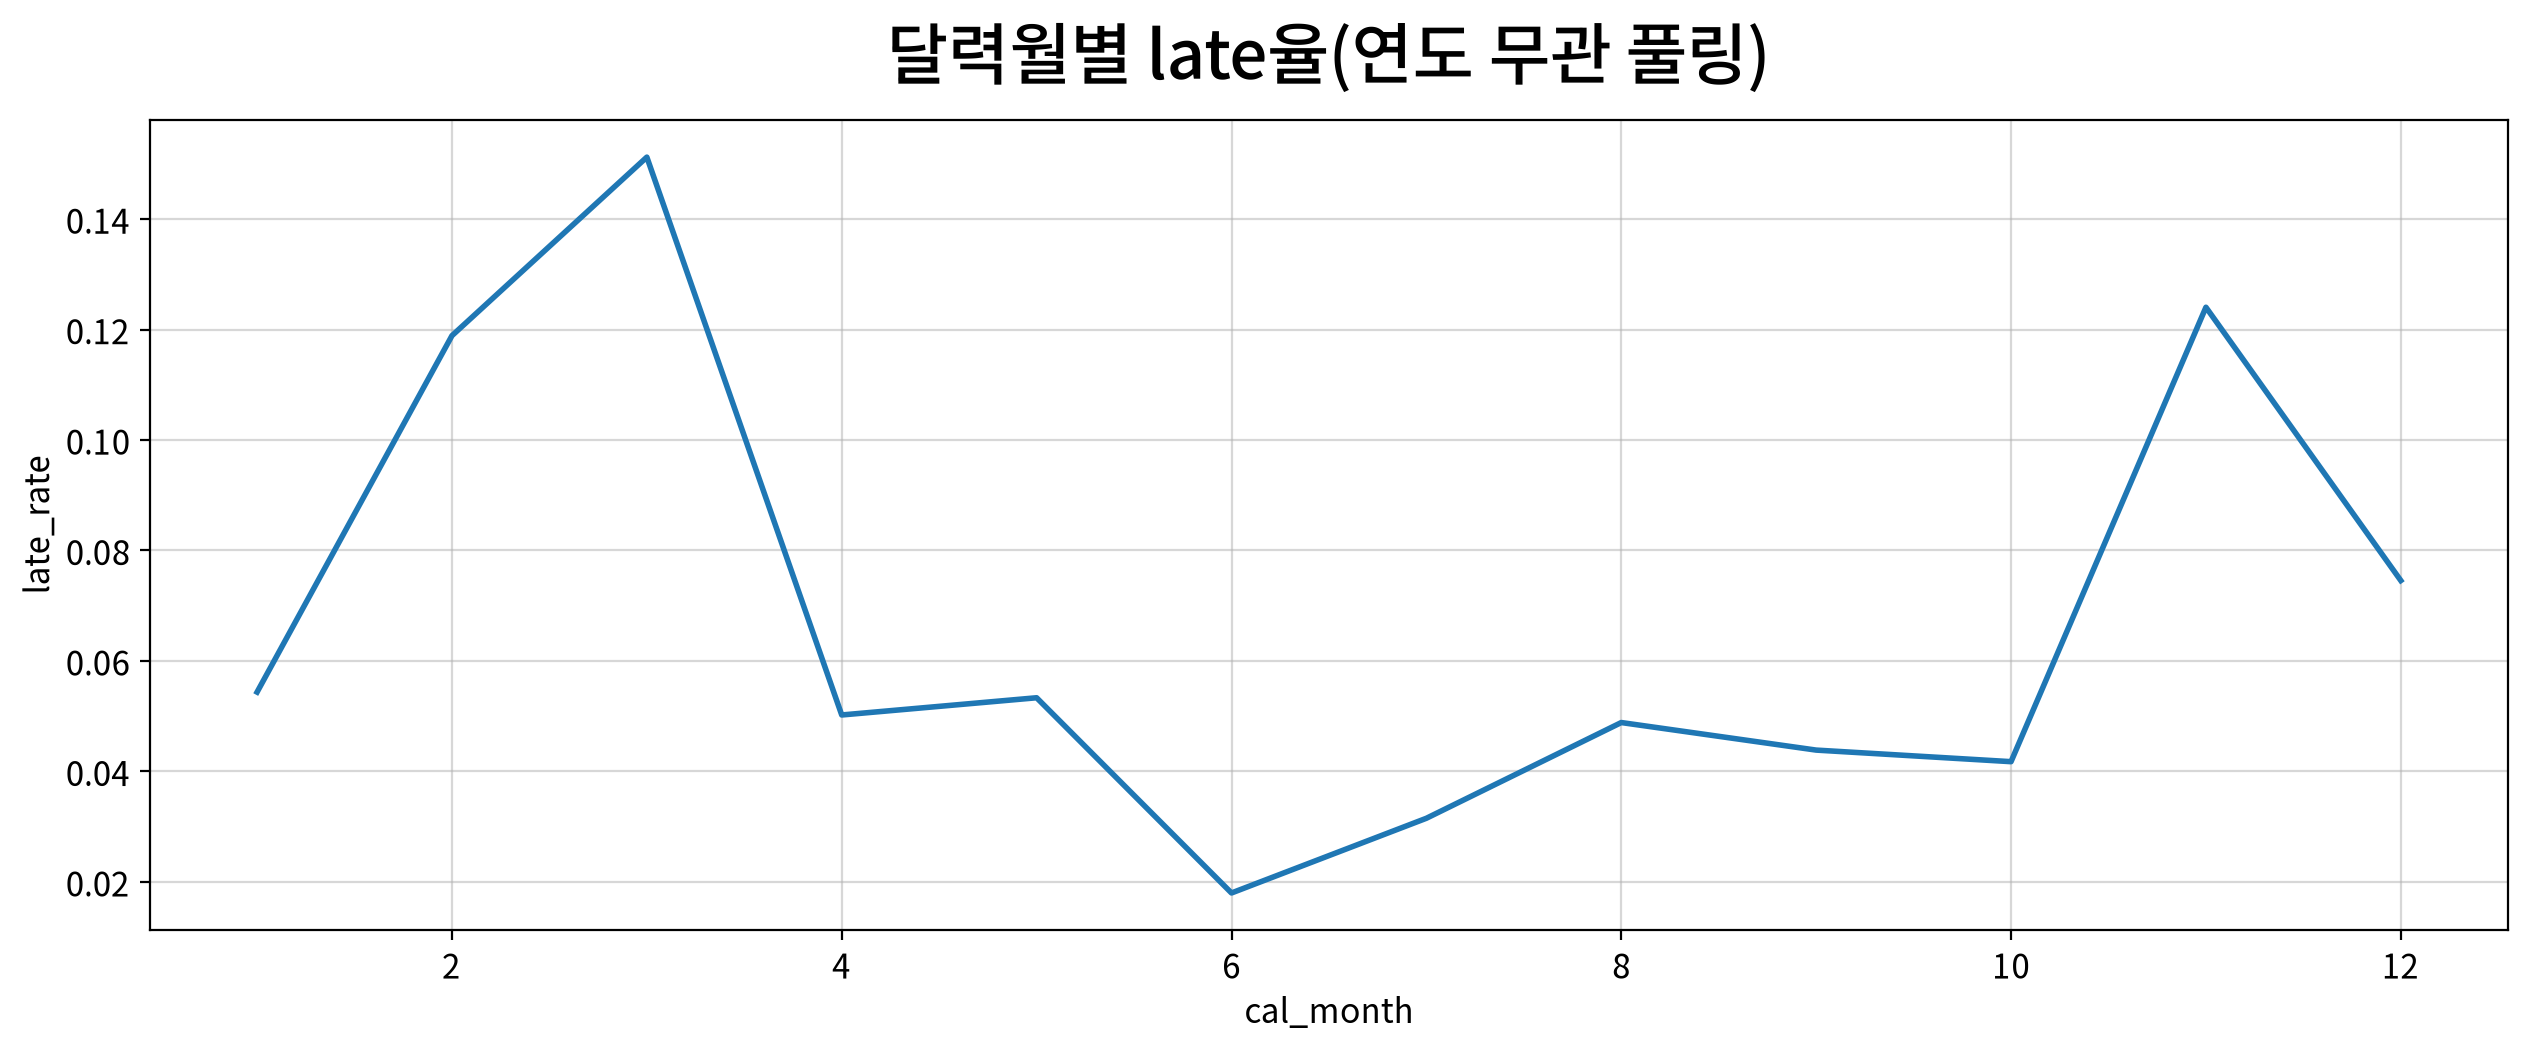

In [2]:
cal = master.assign(cal_month=master["purchase_ts"].dt.month)

monthly_cal = cal.groupby("cal_month").agg(
    n=("order_id", "count"),
    late_rate=("late", "mean"),
    low_rate=("low", "mean"),
)
print(monthly_cal)

my_plot.lineplot(data=monthly_cal.reset_index(), x="cal_month", y="late_rate",
                  title="달력월별 late율(연도 무관 풀링)",
                  save_path="outputs/figures/eda_purchase_month_pooled.png")
# 관찰: 1~3월·11월에 late_rate가 튀는 것처럼 보임 — 다만 n을 보면 9~12월은
# 1~8월(n≈7,800~10,500)보다 확연히 적음(n≈4,150~7,288). 풀링 연도 수가 달라서 생기는
# 착시일 수 있으므로, 결론 내리기 전에 연도별로 쪼개서 재확인해야 함(아래 2번).

## 2. 연도별 분리 — 진짜 계절성인지 연도 효과인지 구분

진짜 달력 계절성이라면 2017년 곡선과 2018년 곡선이 **같은 달 근처에서** 비슷한 모양으로 튀어야 한다. 스파이크 시점이 연도마다 다르면, 그건 "매년 반복되는 계절 패턴"이 아니라 "그 해에만 있었던 개별 사건"일 가능성이 높다.

year           2017      2018
cal_month                    
1          0.029333  0.057009
2          0.029643  0.141397
3          0.045562  0.189633
4          0.065567  0.045013
5          0.029901  0.065639
6          0.030303  0.011647
7          0.027893  0.033788
8          0.029096  0.061880
9          0.043855       NaN
10         0.041760       NaN
11         0.124040       NaN
12         0.074551       NaN


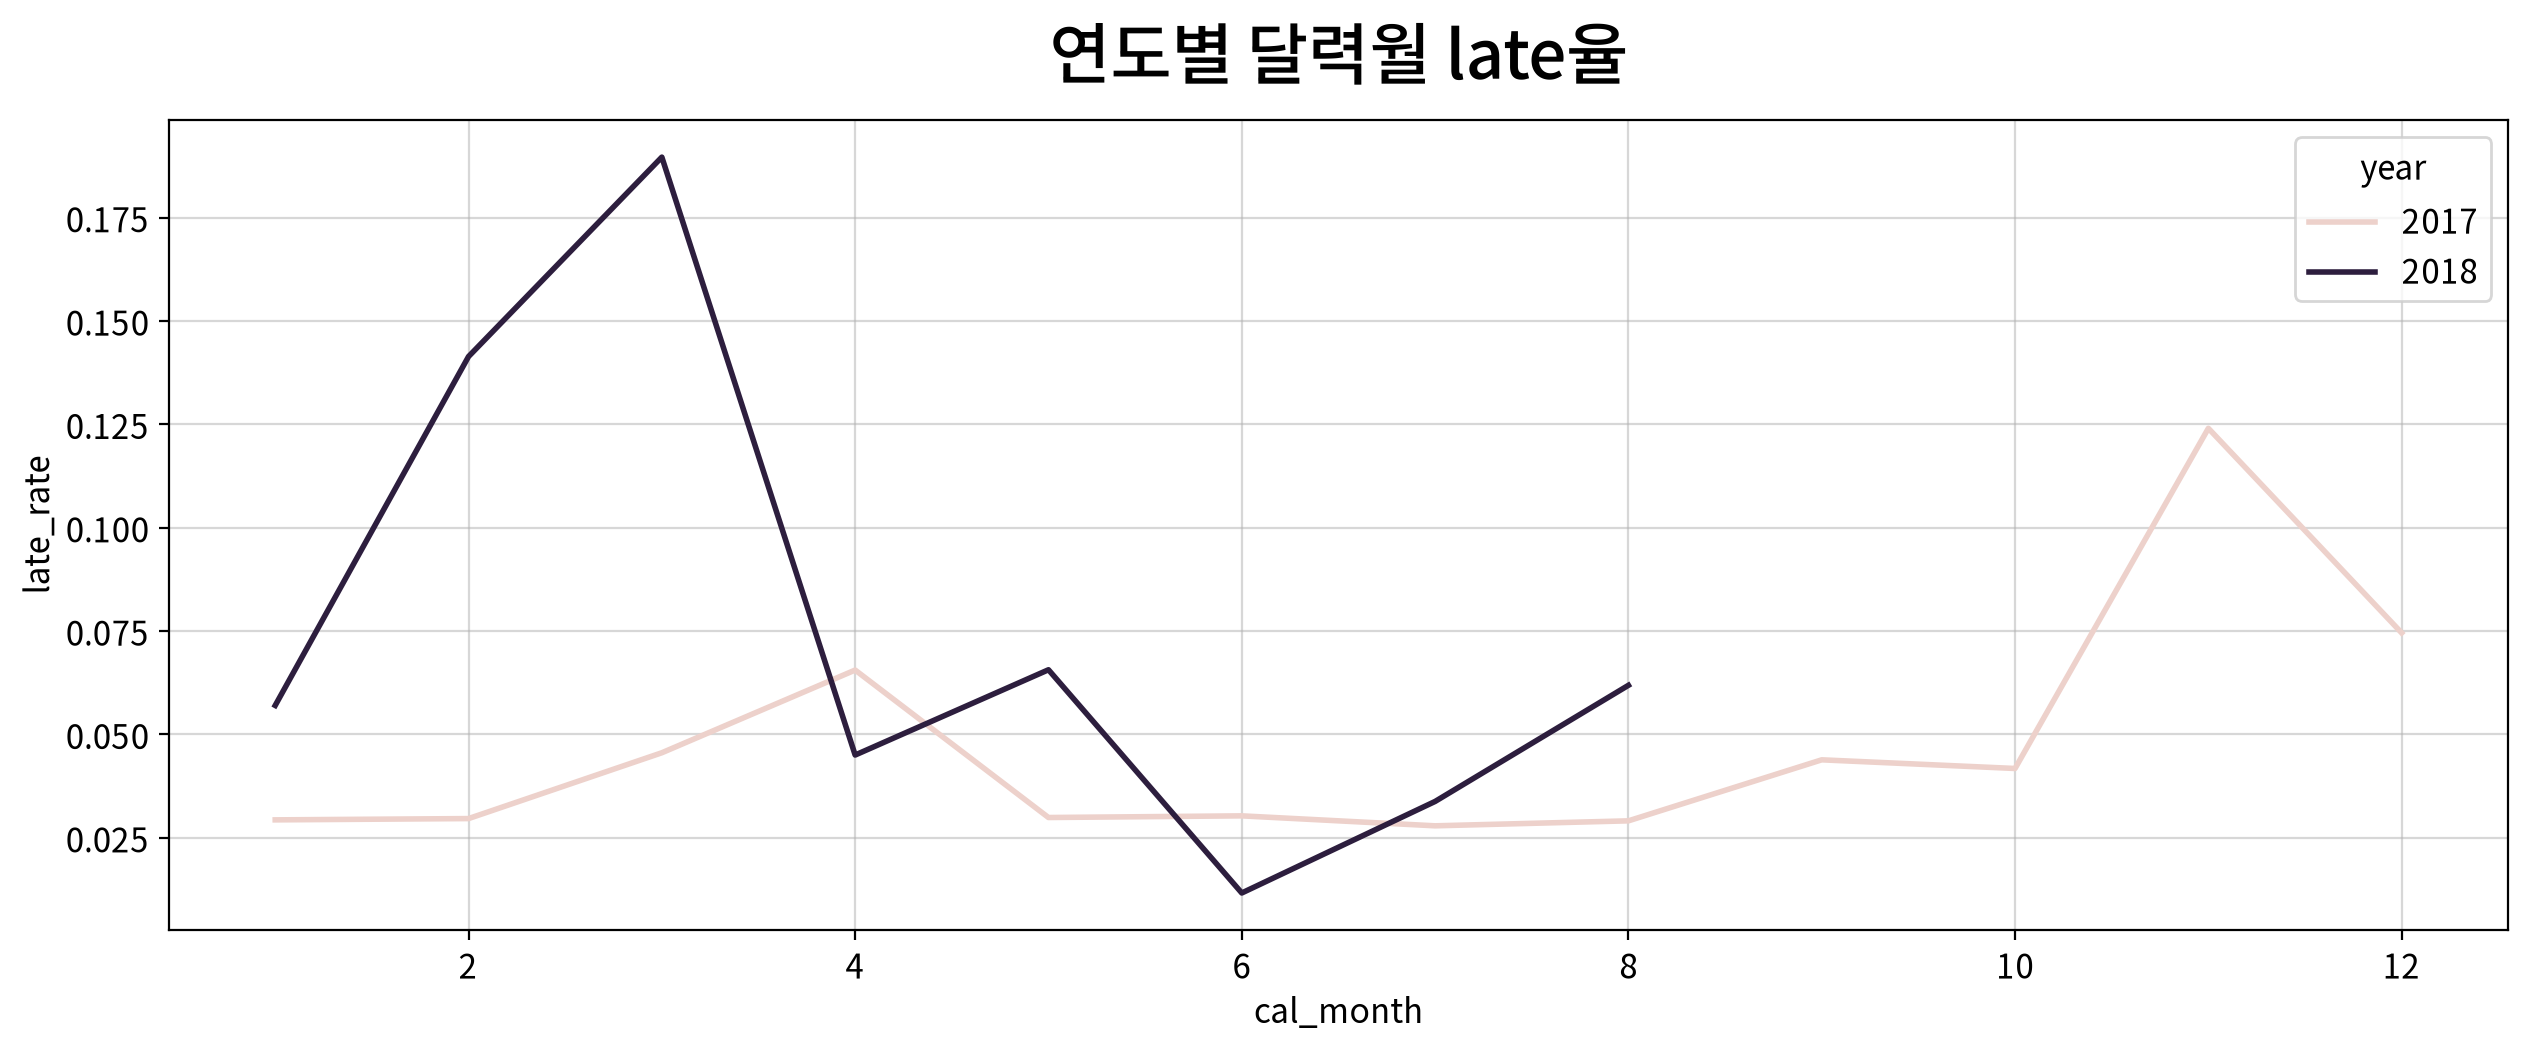

In [3]:
cal2 = master.assign(cal_month=master["purchase_ts"].dt.month,
                      year=master["purchase_ts"].dt.year)

pivot = cal2.groupby(["year", "cal_month"]).agg(
    n=("order_id", "count"), late_rate=("late", "mean")
).reset_index()

pivot_wide = pivot.pivot(index="cal_month", columns="year", values="late_rate")
print(pivot_wide)

my_plot.lineplot(data=pivot, x="cal_month", y="late_rate", hue="year",
                  title="연도별 달력월 late율",
                  save_path="outputs/figures/eda_purchase_month_by_year.png")

# 실행 확인됨(2026-09-27):
# - 2017: 거의 평평(0.03~0.07)하다가 11월에만 급등(12.4%) — 2017-11-24 블랙프라이데이
#   단일 이벤트로 추정
# - 2018: 2~3월에 급등(14.1%→19.0%)했다가 4월에 급락(4.5%) — 11월 스파이크와는
#   전혀 다른 시기·다른 크기
# - 9~12월은 2018년 데이터 자체가 없어(분석기간이 2018-08까지) 연도 비교 불가 구간
# → 두 해의 스파이크가 서로 다른 달에서 발생 = 반복되는 계절성이 아니라 연도별 개별 사건
#   (2018년 2~3월 스파이크의 구체적 원인은 미확인 — log.md에 추후 확인 필요로 기록)

## 3. 결론

**D-15 확정: purchase_month 미사용.**

연도별로 스파이크 시점이 어긋난다는 것이, "월"이라는 변수를 계절 신호(sin/cos 순환 인코딩 또는 범주형)로 넣었을 때 모델이 일회성 사건을 반복 패턴으로 잘못 일반화할 위험이 크다는 뜻이다. 이 위험이 기대되는 이득보다 크다고 판단해 파생변수에서 제외한다. (TimeSeriesSplit는 아직 어느 노트북에서도 쓰고 있지 않음 — Day 6 baseline에서 적용 예정. 적용하게 되면 이런 개별 시점 이벤트는 "월" 변수가 아니라 시간 순서 자체가 다뤄야 할 문제라는 논리는 유효함. [2026-09-30 재정정])